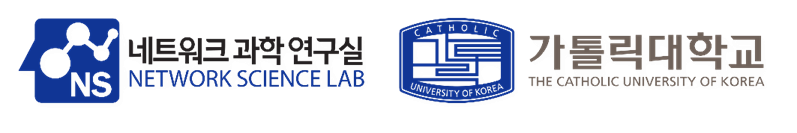


# Solution 3: The Expressive Power of Graph Neural Networks


# Given MUTAG and Practice Code 3

Same tasks as the assignment. MUTAG, 80/20 split (`seed=0`). HASH-GIN if torch is missing.


MUTAG: 188 graphs   classes {1: 125, 0: 63}
  mean n=17.9   mean m=19.8   atom labels [0, 1, 2, 3, 4, 5, 6]
split: train=150  test=38  majority-class test acc=0.737


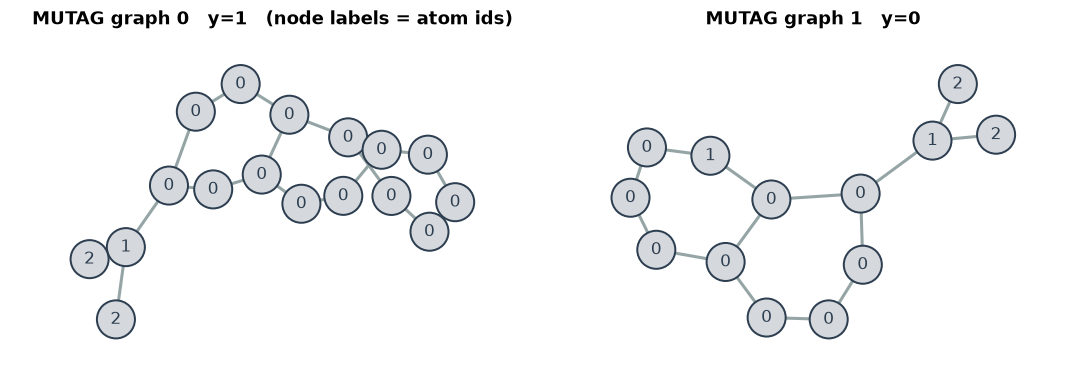

In [2]:
import warnings
warnings.filterwarnings("ignore")

import io
import ssl
import zipfile
from collections import Counter
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

C_TARGET, C_EDGE, C_DARK, C_PLAIN = "#E74C3C", "#95A5A6", "#2C3E50", "#D5D8DC"
_TAB20 = plt.get_cmap("tab20")
_ORDER = [i for i in range(1, 20, 2) if i != 15] + [i for i in range(0, 20, 2) if i != 14]

DATA_DIR = Path.cwd() / "data" / "MUTAG"
MUTAG_URLS = [
    "https://www.chrsmrrs.com/graphkerneldatasets/MUTAG.zip",
    "https://ls11-www.cs.tu-dortmund.de/people/morris/graphkerneldatasets/MUTAG.zip",
]


def color_of(cid):
    return to_rgba(C_PLAIN) if cid == 0 else _TAB20(_ORDER[(int(cid) - 1) % len(_ORDER)])


def ink(rgba):
    r, g, b = rgba[:3]
    return "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else C_DARK


def draw_graph(G, pos, ax, colors=None, labels="id", title=None, highlight=None,
               node_size=620, font_size=11):
    if highlight is None:
        highlight = set()
    elif not isinstance(highlight, (set, list, tuple)):
        highlight = {highlight}
    else:
        highlight = set(highlight)
    nodes = list(G.nodes())
    fill = [color_of(colors[v]) if colors is not None else to_rgba(C_PLAIN) for v in nodes]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=C_EDGE, width=2.0)
    nx.draw_networkx_nodes(
        G, pos, nodelist=nodes, ax=ax, node_color=fill, node_size=node_size,
        edgecolors=[C_TARGET if v in highlight else C_DARK for v in nodes],
        linewidths=[3.0 if v in highlight else 1.3 for v in nodes],
    )
    if labels:
        for v, f in zip(nodes, fill):
            if labels == "id":
                text = v
            elif labels == "atom":
                text = G.nodes[v].get("atom", v)
            else:
                text = colors[v]
            ax.text(*pos[v], str(text), ha="center", va="center", fontsize=font_size,
                    color=ink(f), fontweight="bold" if labels == "color" else "normal")
    if title:
        ax.set_title(title)
    ax.set_axis_off()
    ax.margins(0.15)


def _find_mutag_folder(root: Path) -> Path:
    if (root / "MUTAG_A.txt").exists():
        return root
    nested = root / "MUTAG"
    if (nested / "MUTAG_A.txt").exists():
        return nested
    for path in root.rglob("MUTAG_A.txt"):
        return path.parent
    raise FileNotFoundError("MUTAG_A.txt not found after download")


def download_mutag(dest: Path = DATA_DIR) -> Path:
    dest = Path(dest)
    dest.mkdir(parents=True, exist_ok=True)
    for root in (dest, dest.parent):
        try:
            return _find_mutag_folder(root)
        except FileNotFoundError:
            pass
    last_err = None
    ctx = ssl.create_default_context()
    for url in MUTAG_URLS:
        try:
            print(f"Downloading MUTAG from {url}")
            with urlopen(url, context=ctx, timeout=60) as resp:
                blob = resp.read()
            with zipfile.ZipFile(io.BytesIO(blob)) as zf:
                zf.extractall(dest.parent)
            return _find_mutag_folder(dest.parent)
        except Exception as exc:
            last_err = exc
            print(f"  failed: {exc}")
    try:
        from torch_geometric.datasets import TUDataset
        from torch_geometric.utils import to_networkx
        print("Falling back to torch_geometric.datasets.TUDataset('MUTAG')")
        ds = TUDataset(str(dest.parent / "pyg"), name="MUTAG")
        graphs, y = [], []
        for data in ds:
            G = to_networkx(data, to_undirected=True)
            G = nx.Graph(G)
            atom = data.x.argmax(dim=-1).tolist() if data.x is not None else [1] * G.number_of_nodes()
            for v, a in zip(G.nodes(), atom):
                G.nodes[v]["atom"] = int(a)
            graphs.append(G)
            y.append(int(data.y.item() > 0) if data.y.numel() == 1 else int(data.y[0] > 0))
        return graphs, np.array(y, dtype=int)
    except Exception as exc:
        last_err = f"{last_err}; pyg={exc}"
    raise RuntimeError(f"Could not load MUTAG: {last_err}")


def parse_mutag(folder: Path):
    A = np.loadtxt(folder / "MUTAG_A.txt", delimiter=",", dtype=int)
    gi = np.loadtxt(folder / "MUTAG_graph_indicator.txt", dtype=int)
    gl = np.loadtxt(folder / "MUTAG_graph_labels.txt", dtype=int)
    nl = np.loadtxt(folder / "MUTAG_node_labels.txt", dtype=int)
    nodes_of = {}
    for node, gid in enumerate(gi, start=1):
        nodes_of.setdefault(int(gid), []).append(node)
    gid_of = {node: int(gid) for node, gid in enumerate(gi, start=1)}
    edges_of = {gid: [] for gid in nodes_of}
    for src, dst in A:
        edges_of[gid_of[int(src)]].append((int(src), int(dst)))
    graphs, y = [], []
    for gid in sorted(nodes_of):
        old_nodes = nodes_of[gid]
        remap = {old: i for i, old in enumerate(old_nodes)}
        G = nx.Graph()
        G.add_nodes_from(range(len(old_nodes)))
        for u, v in edges_of[gid]:
            G.add_edge(remap[u], remap[v])
        for i, old in enumerate(old_nodes):
            G.nodes[i]["atom"] = int(nl[old - 1])
        graphs.append(G)
        y.append(0 if int(gl[gid - 1]) < 0 else 1)
    return graphs, np.array(y, dtype=int)


def load_mutag():
    loaded = download_mutag()
    if isinstance(loaded, tuple):
        graphs, y = loaded
    else:
        graphs, y = parse_mutag(loaded)
    n = np.array([G.number_of_nodes() for G in graphs])
    m = np.array([G.number_of_edges() for G in graphs])
    atoms = sorted({G.nodes[v]["atom"] for G in graphs for v in G})
    print(f"MUTAG: {len(graphs)} graphs   classes {dict(Counter(y.tolist()))}")
    print(f"  mean n={n.mean():.1f}   mean m={m.mean():.1f}   atom labels {atoms}")
    return graphs, y


def split_indices(n, seed=0, train_frac=0.8):
    rng = np.random.RandomState(seed)
    idx = rng.permutation(n)
    n_train = int(round(train_frac * n))
    return idx[:n_train], idx[n_train:]


def counters_to_matrix(counters, vocab=None):
    if vocab is None:
        keys = sorted({k for c in counters for k in c}, key=repr)
        vocab = {k: i for i, k in enumerate(keys)}
    X = np.zeros((len(counters), max(len(vocab), 1)), dtype=float)
    for i, c in enumerate(counters):
        for k, cnt in c.items():
            j = vocab.get(k)
            if j is not None:
                X[i, j] = cnt
    return X, vocab


def fit_linear(X_train, y_train, X_test, y_test, name=""):
    try:
        from sklearn.linear_model import LogisticRegression
        clf = LogisticRegression(max_iter=2000, solver="lbfgs")
        clf.fit(X_train, y_train)
        tr = float(clf.score(X_train, y_train))
        te = float(clf.score(X_test, y_test))
    except ImportError:
        Xb = np.c_[X_train, np.ones(len(X_train))]
        w, *_ = np.linalg.lstsq(Xb, y_train.astype(float), rcond=None)
        pred_tr = ((np.c_[X_train, np.ones(len(X_train))] @ w) >= 0.5).astype(int)
        pred_te = ((np.c_[X_test, np.ones(len(X_test))] @ w) >= 0.5).astype(int)
        tr = float((pred_tr == y_train).mean())
        te = float((pred_te == y_test).mean())
    print(f"{name:<28s}  train {tr:.3f}  test {te:.3f}  dim={X_train.shape[1]}")
    return tr, te


def evaluate_counters(make_counter, name, graphs=None, y=None, train_idx=None, test_idx=None):
    graphs = GRAPHS if graphs is None else graphs
    y = Y if y is None else y
    train_idx = TRAIN_IDX if train_idx is None else train_idx
    test_idx = TEST_IDX if test_idx is None else test_idx
    counters = [make_counter(G) for G in graphs]
    _, vocab = counters_to_matrix([counters[i] for i in train_idx])
    X, _ = counters_to_matrix(counters, vocab=vocab)
    tr, te = fit_linear(X[train_idx], y[train_idx], X[test_idx], y[test_idx], name)
    RESULTS[name] = {"train": tr, "test": te, "dim": int(X.shape[1]), "X": X}
    return tr, te, X


def pca_scatter(X, y, title, labels=("class 0", "class 1")):
    Xc = X - X.mean(axis=0)
    _, _, vt = np.linalg.svd(Xc, full_matrices=False)
    xy = Xc @ vt[:2].T
    fig, ax = plt.subplots(figsize=(6.4, 5))
    ax.scatter(xy[y == 0, 0], xy[y == 0, 1], c="#E74C3C", s=55, edgecolors="k", label=labels[0])
    ax.scatter(xy[y == 1, 0], xy[y == 1, 1], c="#3498DB", s=55, edgecolors="k", label=labels[1])
    ax.set_title(title)
    ax.legend()
    ax.set_xticks([])
    ax.set_yticks([])
    plt.tight_layout()
    plt.show()
    return xy


def graph_wl_hash(G, iterations=3, use_atoms=True):
    if use_atoms and all("atom" in G.nodes[v] for v in G):
        return nx.weisfeiler_lehman_graph_hash(G, node_attr="atom", iterations=iterations)
    return nx.weisfeiler_lehman_graph_hash(G, iterations=iterations)


def bag_signature(bag, iterations=3, use_atoms=False):
    """Sorted 1-WL hashes of every subgraph in a bag. Used for C6 vs 2 x C3."""
    return tuple(sorted(graph_wl_hash(H, iterations=iterations, use_atoms=use_atoms) for H in bag))


def pool_counters(subgraphs, fingerprint, prefix):
    """Sum-pool a node/graph Counter over a bag of subgraphs."""
    out = Counter()
    for H in subgraphs:
        for key, cnt in fingerprint(H).items():
            out[(prefix,) + (key if isinstance(key, tuple) else (key,))] += cnt
    return out


C6 = nx.cycle_graph(6)
TwoC3 = nx.disjoint_union(nx.cycle_graph(3), nx.cycle_graph(3))

GRAPHS, Y = load_mutag()
TRAIN_IDX, TEST_IDX = split_indices(len(GRAPHS), seed=0)
maj = Counter(Y[TRAIN_IDX]).most_common(1)[0][0]
MAJ_TEST = float((Y[TEST_IDX] == maj).mean())
RESULTS = {"majority": {"train": float((Y[TRAIN_IDX] == maj).mean()), "test": MAJ_TEST, "dim": 1}}
print(f"split: train={len(TRAIN_IDX)}  test={len(TEST_IDX)}  majority-class test acc={MAJ_TEST:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
draw_graph(GRAPHS[0], nx.spring_layout(GRAPHS[0], seed=0), axes[0], labels="atom",
           title=f"MUTAG graph 0   y={Y[0]}   (node labels = atom ids)")
draw_graph(GRAPHS[1], nx.spring_layout(GRAPHS[1], seed=1), axes[1], labels="atom",
           title=f"MUTAG graph 1   y={Y[1]}")
plt.tight_layout()
plt.show()


## Assignment 1. Implement GIN (HASH-GIN) on MUTAG and visualize the embeddings


C6 vs 2 x C3  (constant features)
  HASH-GIN fingerprints equal? True   (should be True)

MUTAG classification
HASH-GIN (atoms)              train 0.993  test 0.868  dim=708
HASH-GIN (constant)           train 0.940  test 0.868  dim=140
degree histogram              train 0.880  test 0.921  dim=3


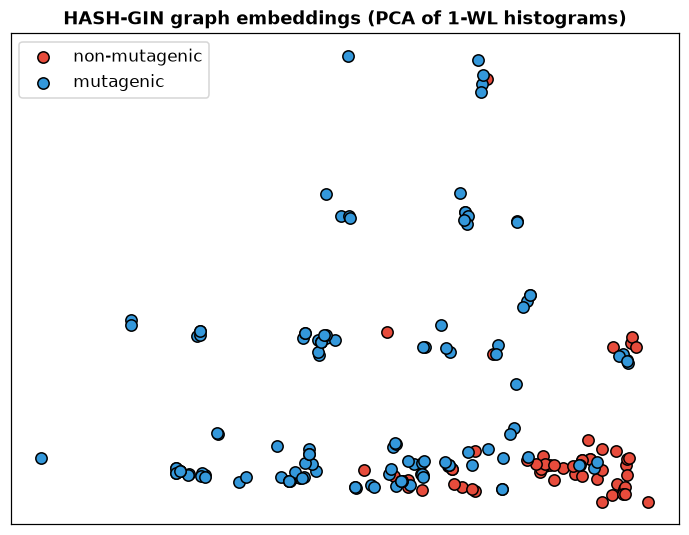

torch GIN device: cuda
optional torch GIN (2 layers, sum readout, atom one-hots)
  step   0  loss  110.660  train acc 0.360
  step  39  loss   65.650  train acc 0.740
  step  79  loss   60.812  train acc 0.807
torch GIN test acc 0.737


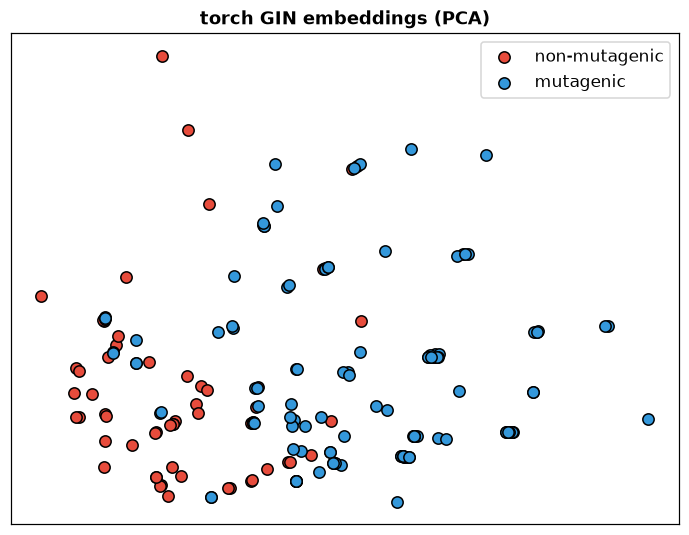

In [3]:
def gin_hash_counter(G, iterations=3, use_atoms=True):
    """HASH-style GIN: identity MLP, injective nested-tuple HASH, layer-wise sum readout."""
    if use_atoms:
        colors = {v: ("atom", int(G.nodes[v].get("atom", 1))) for v in G}
    else:
        colors = {v: ("const", 1) for v in G}
    total = Counter()
    for t in range(iterations + 1):
        total.update((t, colors[v]) for v in G)
        nxt = {}
        for v in G:
            nbrs = tuple(sorted(colors[u] for u in G[v]))
            nxt[v] = (colors[v], nbrs)
        colors = nxt
    return total


print("C6 vs 2 x C3  (constant features)")
c6 = gin_hash_counter(C6, use_atoms=False)
two = gin_hash_counter(TwoC3, use_atoms=False)
print(f"  HASH-GIN fingerprints equal? {c6 == two}   (should be True)")

print("\nMUTAG classification")
evaluate_counters(lambda G: gin_hash_counter(G, use_atoms=True), "HASH-GIN (atoms)")
evaluate_counters(lambda G: gin_hash_counter(G, use_atoms=False), "HASH-GIN (constant)")
evaluate_counters(
    lambda G: Counter({("deg", d): n for d, n in Counter(dict(G.degree()).values()).items()}),
    "degree histogram",
)

X = RESULTS["HASH-GIN (atoms)"]["X"]
pca_scatter(X, Y, "HASH-GIN graph embeddings (PCA of 1-WL histograms)",
            labels=("non-mutagenic", "mutagenic"))


try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F

    torch.manual_seed(0)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"torch GIN device: {device}")

    atoms = sorted({G.nodes[v]["atom"] for G in GRAPHS for v in G})
    atom_index = {a: i for i, a in enumerate(atoms)}
    n_atom = len(atoms)

    def from_nx(G):
        x = torch.zeros(G.number_of_nodes(), n_atom, device=device)
        for v in G:
            x[v, atom_index[G.nodes[v]["atom"]]] = 1.0
        src, dst = [], []
        for u, v in G.edges():
            src.extend([u, v])
            dst.extend([v, u])
        edge_index = (torch.tensor([src, dst], dtype=torch.long, device=device)
                      if src else torch.zeros(2, 0, dtype=torch.long, device=device))
        return x, edge_index

    class GINConv(nn.Module):
        def __init__(self, in_dim, out_dim):
            super().__init__()
            self.mlp = nn.Sequential(nn.Linear(in_dim, out_dim), nn.ReLU(), nn.Linear(out_dim, out_dim))
            self.eps = nn.Parameter(torch.zeros(1))

        def forward(self, x, edge_index):
            agg = torch.zeros_like(x)
            if edge_index.numel():
                src, dst = edge_index
                agg.index_add_(0, dst, x[src])
            return self.mlp((1.0 + self.eps) * x + agg)

    class GIN(nn.Module):
        def __init__(self, hidden=32, num_layers=2, num_classes=2):
            super().__init__()
            dims = [n_atom] + [hidden] * num_layers
            self.convs = nn.ModuleList(GINConv(dims[i], dims[i + 1]) for i in range(num_layers))
            self.readout = nn.Linear(hidden * num_layers, num_classes)

        def forward(self, x, edge_index, embed=False):
            xs, h = [], x
            for conv in self.convs:
                h = conv(h, edge_index)
                xs.append(h)
            g = torch.cat([t.sum(dim=0) for t in xs], dim=0)
            if embed:
                return g
            return self.readout(g)

    data = [from_nx(G) for G in GRAPHS]
    y_t = torch.tensor(Y, dtype=torch.long, device=device)
    gin = GIN().to(device)
    opt = torch.optim.Adam(gin.parameters(), lr=0.01)
    print("optional torch GIN (2 layers, sum readout, atom one-hots)")
    for step in range(80):
        gin.train()
        opt.zero_grad()
        loss = torch.zeros((), device=device)
        correct = 0
        for i in TRAIN_IDX:
            logits = gin(*data[i])
            loss = loss + F.cross_entropy(logits.unsqueeze(0), y_t[i].unsqueeze(0))
            correct += int(logits.argmax().item() == y_t[i].item())
        loss.backward()
        opt.step()
        if step in (0, 39, 79):
            print(f"  step {step:3d}  loss {loss.item():8.3f}  train acc {correct / len(TRAIN_IDX):.3f}")
    gin.eval()
    with torch.no_grad():
        pred = np.array([int(gin(*data[i]).argmax().item()) for i in TEST_IDX])
        te = float((pred == Y[TEST_IDX]).mean())
        embs = np.stack([gin(*data[i], embed=True).cpu().numpy() for i in range(len(GRAPHS))])
    print(f"torch GIN test acc {te:.3f}")
    RESULTS["torch GIN"] = {"train": correct / len(TRAIN_IDX), "test": te, "dim": embs.shape[1], "X": embs}
    pca_scatter(embs, Y, "torch GIN embeddings (PCA)", labels=("non-mutagenic", "mutagenic"))
except ImportError:
    print("torch is not installed; HASH-GIN + linear classifier is the required solution.")

Constant HASH-GIN cannot split $C_6$ vs $2\times C_3$ (same as 1-WL). MUTAG accuracy will move a bit with the split; 38 test graphs is small.


## Assignment 2. Implement GSN cycle features on MUTAG


In [4]:
def cycle_features(G, lengths=(3, 4, 5, 6)):
    """How many undirected k-cycles contain each vertex (GSN-v for H = C_k)."""
    feat = {v: {L: 0 for L in lengths} for v in G.nodes()}
    seen = set()
    for cyc in nx.simple_cycles(G.to_directed()):
        L = len(cyc)
        if L not in lengths:
            continue
        rot = tuple(cyc)
        fwd = min(rot[i:] + rot[:i] for i in range(L))
        rev = tuple(reversed(rot))
        bwd = min(rev[i:] + rev[:i] for i in range(L))
        key = min(fwd, bwd)
        if key in seen:
            continue
        seen.add(key)
        for v in cyc:
            feat[v][L] += 1
    return feat


def gsn_counter(G, lengths=(3, 4, 5, 6)):
    feat = cycle_features(G, lengths)
    total = Counter()
    for L in lengths:
        total[("sumC", L)] = sum(feat[v][L] for v in G)
    for v in G:
        total[("nodeC", tuple(feat[v][L] for L in lengths))] += 1
    return total


print("C6 vs 2 x C3")
print(f"  GSN fingerprints equal? {gsn_counter(C6) == gsn_counter(TwoC3)}   (should be False)")
print(f"    C6   {dict(gsn_counter(C6))}")
print(f"    2C3  {dict(gsn_counter(TwoC3))}")

print("\nMUTAG classification")
evaluate_counters(gsn_counter, "GSN C3-C6")

wl = [tuple(sorted(gin_hash_counter(GRAPHS[i], use_atoms=False).items())) for i in TRAIN_IDX]
gsn = [tuple(sorted(gsn_counter(GRAPHS[i]).items())) for i in TRAIN_IDX]
n_same, n_split = 0, 0
for a in range(len(TRAIN_IDX)):
    for b in range(a + 1, len(TRAIN_IDX)):
        if wl[a] == wl[b]:
            n_same += 1
            if gsn[a] != gsn[b]:
                n_split += 1
print(f"\ntrain pairs with identical constant HASH-GIN: {n_same}")
print(f"  of those, GSN fingerprints differ:          {n_split}")


C6 vs 2 x C3
  GSN fingerprints equal? False   (should be False)
    C6   {('sumC', 3): 0, ('sumC', 4): 0, ('sumC', 5): 0, ('sumC', 6): 6, ('nodeC', (0, 0, 0, 1)): 6}
    2C3  {('sumC', 3): 6, ('sumC', 4): 0, ('sumC', 5): 0, ('sumC', 6): 0, ('nodeC', (1, 0, 0, 0)): 6}

MUTAG classification
GSN C3-C6                     train 0.873  test 0.895  dim=11

train pairs with identical constant HASH-GIN: 56
  of those, GSN fingerprints differ:          0


GSN: $C_6$ has 6-cycles, $2\times C_3$ has triangles. Message passing is unchanged.


## Assignment 3. Implement GNN-AK egonets on MUTAG


C6 vs 2 x C3  (induced 1-hop egonet of node 0)
  C6   n=3 m=2  edges among neighbors=0
  2C3  n=3 m=3  edges among neighbors=1
  bag signatures equal? False   (should be False)


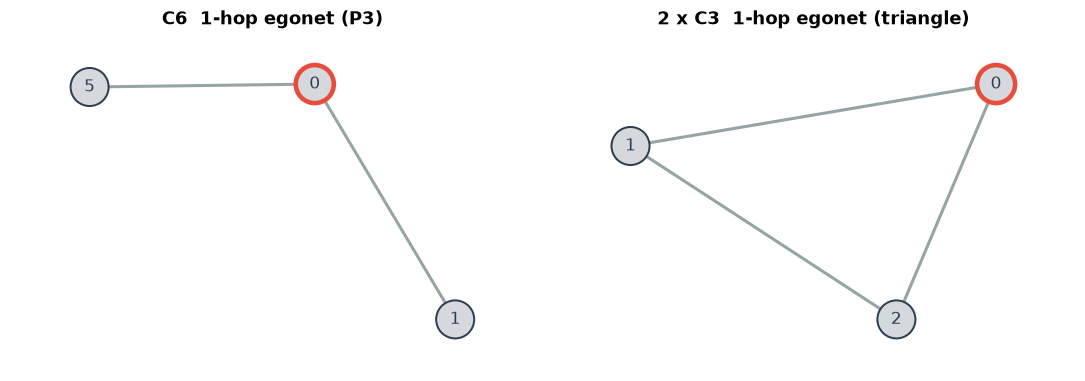


MUTAG classification
GNN-AK 1-hop                  train 0.933  test 0.895  dim=108


(0.9333333333333333,
 0.8947368421052632,
 array([[47.,  4.,  4., ...,  0.,  0.,  0.],
        [30.,  7.,  4., ...,  0.,  0.,  0.],
        [30.,  7.,  4., ...,  0.,  0.,  0.],
        ...,
        [27.,  7.,  4., ...,  0.,  0.,  0.],
        [61.,  4.,  4., ...,  0.,  0.,  0.],
        [41.,  7.,  4., ...,  0.,  0.,  0.]], shape=(188, 108)))

In [5]:
def k_egonet(G, v, k=1):
    dist = nx.single_source_shortest_path_length(G, v, cutoff=k)
    return G.subgraph(list(dist)).copy()


def node_deleted_bag(G):
    return [G.subgraph([u for u in G if u != v]).copy() for v in G]


def ak_counter(G, k=1, use_atoms=True):
    bag = [k_egonet(G, v, k=k) for v in G]
    return pool_counters(bag, lambda H: gin_hash_counter(H, iterations=2, use_atoms=use_atoms), "ak")


def esan_counter(G, use_atoms=True):
    return pool_counters(
        node_deleted_bag(G),
        lambda H: gin_hash_counter(H, iterations=2, use_atoms=use_atoms),
        "es",
    )


print("C6 vs 2 x C3  (induced 1-hop egonet of node 0)")
E1, E2 = k_egonet(C6, 0, k=1), k_egonet(TwoC3, 0, k=1)
print(f"  C6   n={E1.number_of_nodes()} m={E1.number_of_edges()}  "
      f"edges among neighbors={E1.number_of_edges() - C6.degree(0)}")
print(f"  2C3  n={E2.number_of_nodes()} m={E2.number_of_edges()}  "
      f"edges among neighbors={E2.number_of_edges() - TwoC3.degree(0)}")
print(f"  bag signatures equal? "
      f"{bag_signature([k_egonet(C6, v, 1) for v in C6]) == bag_signature([k_egonet(TwoC3, v, 1) for v in TwoC3])}"
      f"   (should be False)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
draw_graph(E1, nx.spring_layout(E1, seed=0), axes[0], highlight=0, title="C6  1-hop egonet (P3)")
draw_graph(E2, nx.spring_layout(E2, seed=1), axes[1], highlight=0, title="2 x C3  1-hop egonet (triangle)")
plt.tight_layout()
plt.show()

print("\nMUTAG classification")
evaluate_counters(lambda G: ak_counter(G, k=1, use_atoms=True), "GNN-AK 1-hop")


Induced 1-hop egonet of node 0 is $P_3$ in $C_6$ and a triangle in $2\times C_3$.


## Assignment 4. Implement ESAN node-deleted bags on MUTAG


C6 vs 2 x C3  (node-deleted bags)
  C6   ('29e26218b9662ab1f09f534283c863cf', '29e26218b9662ab1f09f534283c863cf', '29e26218b9662ab1f09f534283c863cf', '29e26218b9662ab1f09f534283c863cf', '29e26218b9662ab1f09f534283c863cf', '29e26218b9662ab1f09f534283c863cf')
  2C3  ('c271adac5fb798de67e0dfc342655371', 'c271adac5fb798de67e0dfc342655371', 'c271adac5fb798de67e0dfc342655371', 'c271adac5fb798de67e0dfc342655371', 'c271adac5fb798de67e0dfc342655371', 'c271adac5fb798de67e0dfc342655371')
  bags equal? False   (should be False)


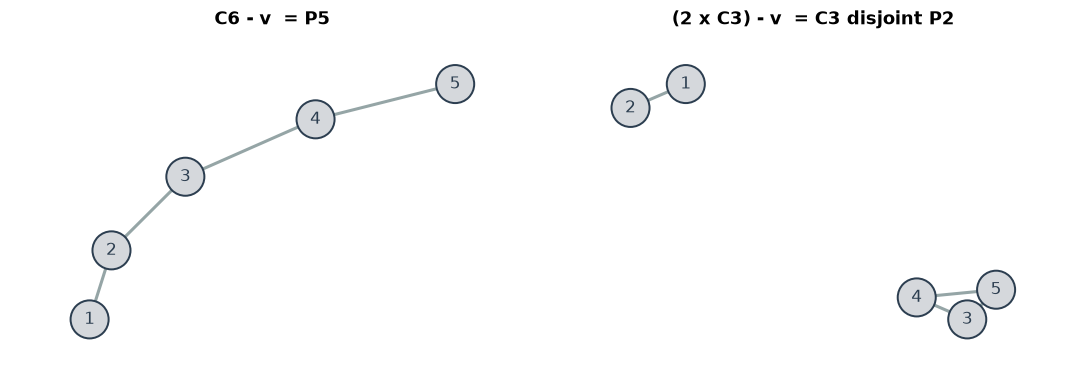


MUTAG classification
ESAN node-del                 train 0.993  test 0.895  dim=474


(0.9933333333333333,
 0.8947368421052632,
 array([[224.,  16.,  32., ...,   0.,   0.,   0.],
        [108.,  24.,  24., ...,   0.,   0.,   0.],
        [108.,  24.,  24., ...,   0.,   0.,   0.],
        ...,
        [ 88.,  22.,  22., ...,   0.,   0.,   0.],
        [360.,  20.,  40., ...,   0.,   0.,   0.],
        [180.,  30.,  30., ...,   0.,   0.,   0.]], shape=(188, 474)))

In [6]:
print("C6 vs 2 x C3  (node-deleted bags)")
sig1, sig2 = bag_signature(node_deleted_bag(C6)), bag_signature(node_deleted_bag(TwoC3))
print(f"  C6   {sig1}")
print(f"  2C3  {sig2}")
print(f"  bags equal? {sig1 == sig2}   (should be False)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
draw_graph(node_deleted_bag(C6)[0], nx.spring_layout(node_deleted_bag(C6)[0], seed=0),
           axes[0], title="C6 - v  = P5")
draw_graph(node_deleted_bag(TwoC3)[0], nx.spring_layout(node_deleted_bag(TwoC3)[0], seed=1),
           axes[1], title="(2 x C3) - v  = C3 disjoint P2")
plt.tight_layout()
plt.show()

print("\nMUTAG classification")
evaluate_counters(lambda G: esan_counter(G, use_atoms=True), "ESAN node-del")


$C_6-v$ is $P_5$; $(2\times C_3)-v$ is $C_3 \sqcup P_2$. Ordinary 1-WL already separates those, so the bags differ.


## Comparison


In [7]:
print(f"{'method':<28s}  {'train':>7s}  {'test':>7s}  {'dim':>5s}")
print("-" * 54)
for name, row in RESULTS.items():
    print(f"{name:<28s}  {row['train']:7.3f}  {row['test']:7.3f}  {row['dim']:5d}")


method                          train     test    dim
------------------------------------------------------
majority                        0.647    0.737      1
HASH-GIN (atoms)                0.993    0.868    708
HASH-GIN (constant)             0.940    0.868    140
degree histogram                0.880    0.921      3
torch GIN                       0.807    0.737     64
GSN C3-C6                       0.873    0.895     11
GNN-AK 1-hop                    0.933    0.895    108
ESAN node-del                   0.993    0.895    474
